# Data Preprocessing

Turns the raw UCI Appliances Energy Prediction file into the hourly, four-zone readings table that the backend and the model training notebook use. The logic matches `backend/app/data/real_dataset.py`.

## 1. Setup

In [1]:
!pip install -q pandas numpy matplotlib


In [2]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATASET_URL = "https://raw.githubusercontent.com/LuisM78/Appliances-energy-prediction-data/master/energydata_complete.csv"
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
RAW_PATH = RAW_DIR / "energydata_complete.csv"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


## 2. Download the raw dataset

In [3]:
if not RAW_PATH.exists():
    urllib.request.urlretrieve(DATASET_URL, RAW_PATH)

raw = pd.read_csv(RAW_PATH, parse_dates=["date"]).set_index("date").sort_index()
print(raw.shape)
raw.head()


(19735, 28)


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


## 3. Resample to hourly

The source data is logged every 10 minutes. `Appliances` and `lights` (Wh) are summed per hour;
temperature/humidity sensors and the weather columns are averaged.

In [4]:
sum_cols = ["Appliances", "lights"]
mean_cols = [c for c in raw.columns if c not in sum_cols and c not in ("rv1", "rv2")]

hourly = pd.concat(
    [raw[sum_cols].resample("h").sum(), raw[mean_cols].resample("h").mean()],
    axis=1,
).dropna()

print(hourly.shape)
hourly.head()


(3290, 26)


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,330,210,19.890000,46.502778,19.200000,44.626528,19.790000,44.897778,18.932778,45.738750,...,18.150000,48.710556,17.016667,45.446667,6.308333,733.750000,92.000000,6.166667,53.416667,5.050000
2016-01-11 18:00:00,1060,310,19.897778,45.879028,19.268889,44.438889,19.770000,44.863333,18.908333,46.066667,...,18.094444,48.597222,16.981667,45.290000,5.941667,734.266667,91.583333,5.416667,40.000000,4.658333
2016-01-11 19:00:00,1040,150,20.495556,52.805556,19.925556,46.061667,20.052222,47.227361,18.969444,47.815556,...,18.156111,49.213333,16.902222,45.311389,6.000000,734.791667,89.750000,6.000000,40.000000,4.391667
2016-01-11 20:00:00,750,210,20.961111,48.453333,20.251111,45.632639,20.213889,47.268889,19.190833,49.227917,...,18.773333,50.195556,16.890000,45.118889,6.000000,735.283333,87.583333,6.000000,40.000000,4.016667
2016-01-11 21:00:00,620,140,21.311667,45.768333,20.587778,44.961111,20.373333,46.164444,19.425556,47.918889,...,19.153333,49.542222,16.890000,44.807778,5.833333,735.566667,87.416667,6.000000,40.000000,3.816667


## 4. Split the single meter into four zones

The dataset has one whole-house `Appliances`/`lights` meter but eight room temperature/humidity
sensor pairs. Each of the four floors is mapped to two of those sensor pairs.

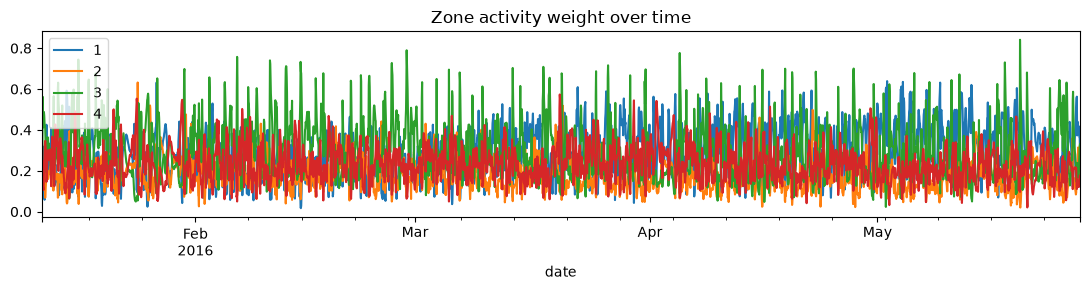

In [5]:
ZONES = {
    1: {"label": "Kitchen & Living", "temp": ["T1", "T2"], "rh": ["RH_1", "RH_2"]},
    2: {"label": "Utility & Office", "temp": ["T3", "T4"], "rh": ["RH_3", "RH_4"]},
    3: {"label": "Bath & Ironing", "temp": ["T5", "T7"], "rh": ["RH_5", "RH_7"]},
    4: {"label": "Bedrooms", "temp": ["T8", "T9"], "rh": ["RH_8", "RH_9"]},
}
ROLLING_WINDOW_HOURS = 24


def zone_activity(hourly: pd.DataFrame) -> pd.DataFrame:
    scores = pd.DataFrame(index=hourly.index)
    for floor, zone in ZONES.items():
        temp_dev = sum(
            (hourly[t] - hourly[t].rolling(ROLLING_WINDOW_HOURS, min_periods=4).mean()).abs()
            for t in zone["temp"]
        ) / len(zone["temp"])
        rh_dev = sum(
            (hourly[r] - hourly[r].rolling(ROLLING_WINDOW_HOURS, min_periods=4).mean()).abs()
            for r in zone["rh"]
        ) / len(zone["rh"])
        scores[floor] = (temp_dev.fillna(0) + 0.3 * rh_dev.fillna(0)) + 1e-3
    return scores


activity = zone_activity(hourly)
weights = activity.div(activity.sum(axis=1), axis=0)
weights.plot(figsize=(11, 3), title="Zone activity weight over time")
plt.tight_layout()
plt.show()


## 5. Build the per-floor readings table

Two things here are derived rather than measured, and both are worth knowing:

* The zone loads are an allocation of the single house meter. They add up exactly to the metered total, but they are not real submetering.
* The dataset has no occupancy sensor. `occupancy` is the percentile rank of the zone's own hourly load, scaled to 0 to 6, so it behaves like an activity indicator and carries information about the current reading.

In [6]:
appliances_kwh = hourly["Appliances"] / 1000.0
lights_kwh = hourly["lights"] / 1000.0

rows = []
for floor in ZONES:
    floor_plug = (weights[floor] * appliances_kwh).round(4)
    floor_lighting = (weights[floor] * lights_kwh).round(4)
    floor_total = (floor_plug + floor_lighting).round(4)

    percentile = floor_total.rank(pct=True)
    occupancy = (percentile * 6).round().astype(int)

    rows.append(pd.DataFrame({
        "floor": floor,
        "zone_label": ZONES[floor]["label"],
        "ts": hourly.index,
        "total_kwh": floor_total.to_numpy(),
        "lighting_kwh": floor_lighting.to_numpy(),
        "plug_kwh": floor_plug.to_numpy(),
        "hvac_kwh": 0.0,
        "elevator_kwh": 0.0,
        "outdoor_temp_c": hourly["T_out"].round(2).to_numpy(),
        "humidity_pct": hourly["RH_out"].clip(0, 100).round(1).to_numpy(),
        "occupancy": occupancy.to_numpy(),
    }))

readings = pd.concat(rows, ignore_index=True)
print(readings.shape)
readings.head()

# sanity check: the four zones must add up to the metered house total
house_total = (appliances_kwh + lights_kwh).round(4)
zone_sum = readings.groupby("ts")["total_kwh"].sum()
print("Max difference between zone sum and house total (kWh):", float((zone_sum - house_total).abs().max()))


(13160, 11)
Max difference between zone sum and house total (kWh): 0.00020000000000020002


## 6. Exploratory Data Analysis (EDA)

### 6.1 Data quality — missing values and duplicate timestamps

In [7]:
print("Missing values per column:")
print(readings.isna().sum())
print()
dup = readings.duplicated(subset=["floor", "ts"]).sum()
print(f"Duplicate (floor, ts) rows: {dup}")
print()
print(f"Date range: {readings['ts'].min()} to {readings['ts'].max()}")
print(f"Rows per floor: {readings.groupby('floor').size().to_dict()}")


Missing values per column:
floor             0
zone_label        0
ts                0
total_kwh         0
lighting_kwh      0
plug_kwh          0
hvac_kwh          0
elevator_kwh      0
outdoor_temp_c    0
humidity_pct      0
occupancy         0
dtype: int64

Duplicate (floor, ts) rows: 0

Date range: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Rows per floor: {1: 3290, 2: 3290, 3: 3290, 4: 3290}


### 6.2 Summary statistics per zone

In [8]:
readings.groupby("zone_label")["total_kwh"].describe()


,count,mean,std,min,25%,50%,75%,max
zone_label,,,,,,,,
Bath & Ironing,3290.0,0.183108,0.181508,0.0074,0.073900,0.11990,0.217425,2.3062
Bedrooms,3290.0,0.136285,0.118336,0.0081,0.067350,0.09605,0.160000,1.4205
Kitchen & Living,3290.0,0.171552,0.154978,0.0070,0.080600,0.12310,0.197975,1.3437
Utility & Office,3290.0,0.117882,0.138783,0.0074,0.045625,0.06840,0.129450,1.7002


### 6.3 Distribution of hourly consumption per zone

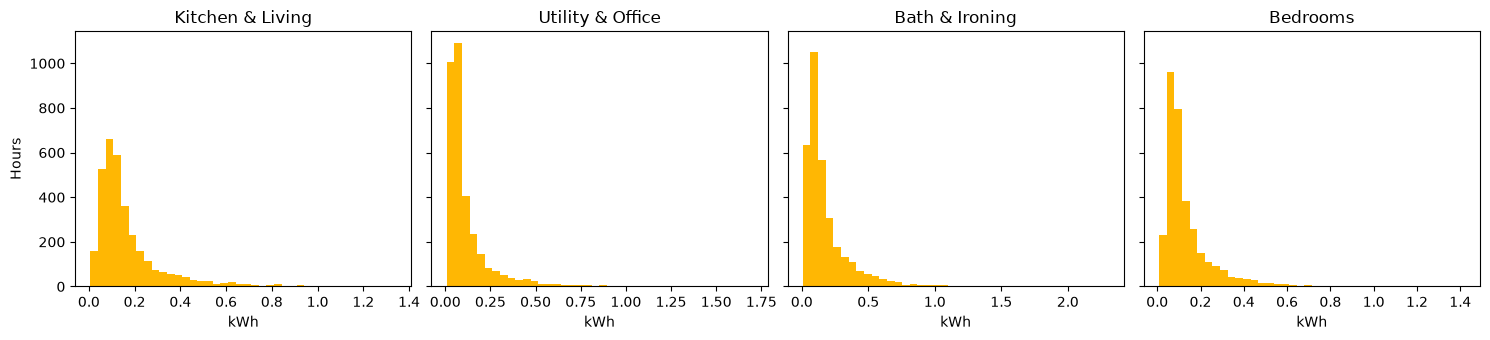

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, (floor, zone) in zip(axes, ZONES.items()):
    subset = readings[readings["floor"] == floor]["total_kwh"]
    ax.hist(subset, bins=40, color="#ffb703")
    ax.set_title(zone["label"])
    ax.set_xlabel("kWh")
axes[0].set_ylabel("Hours")
plt.tight_layout()
plt.show()


### 6.4 24-hour rolling mean consumption per zone

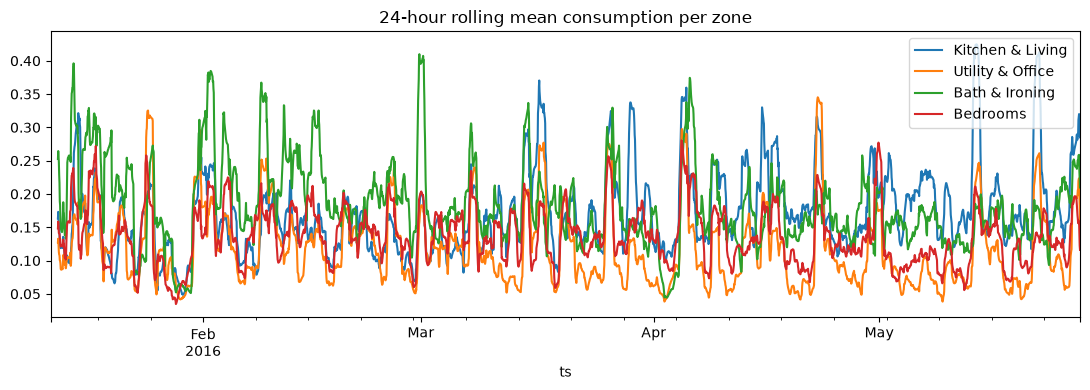

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
for floor, zone in ZONES.items():
    subset = readings[readings["floor"] == floor].set_index("ts")["total_kwh"]
    subset.rolling(24).mean().plot(ax=ax, label=zone["label"])
ax.set_title("24-hour rolling mean consumption per zone")
ax.legend()
plt.tight_layout()
plt.show()


### 6.5 Time-of-day and day-of-week patterns

Boxplots of total consumption (all zones pooled) by hour of day and by day of week, to check for
the diurnal/weekly structure the forecasting models rely on via `hour_sin`/`hour_cos`/`dow_sin`/`dow_cos`.

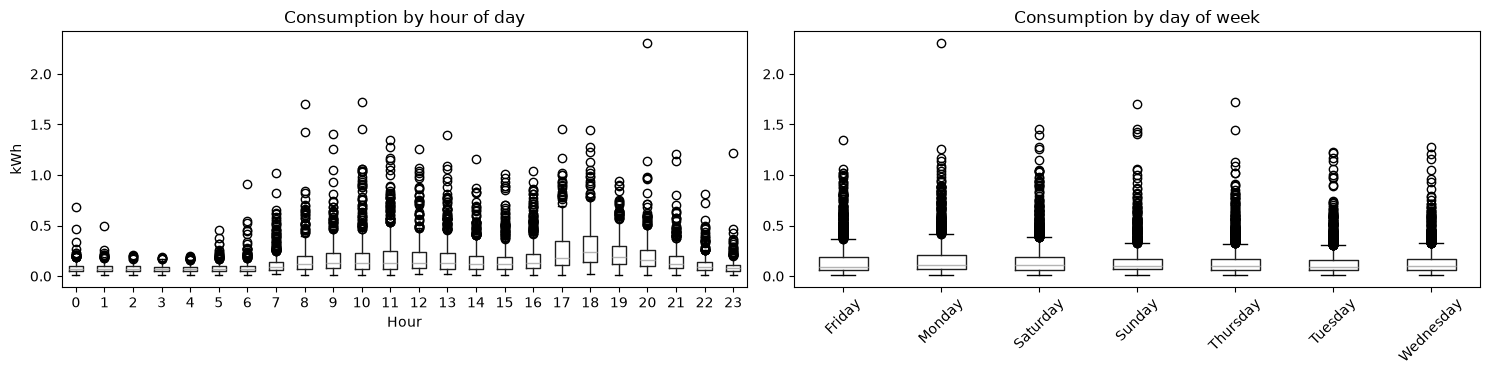

In [11]:
readings["hour"] = readings["ts"].dt.hour
readings["dow"] = readings["ts"].dt.day_name()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
readings.boxplot(column="total_kwh", by="hour", ax=axes[0], grid=False)
axes[0].set_title("Consumption by hour of day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("kWh")

dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
readings.boxplot(column="total_kwh", by="dow", ax=axes[1], grid=False)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
axes[1].set_title("Consumption by day of week")
axes[1].set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()


### 6.6 Hour x day-of-week heatmap

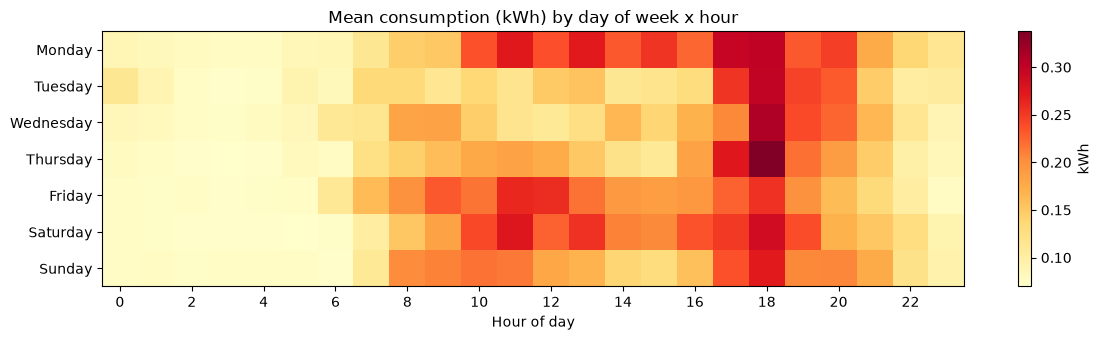

In [12]:
pivot = readings.pivot_table(index="dow", columns="hour", values="total_kwh", aggfunc="mean").reindex(dow_order)
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(pivot.to_numpy(), aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(range(0, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_title("Mean consumption (kWh) by day of week x hour")
fig.colorbar(im, ax=ax, label="kWh")
plt.tight_layout()
plt.show()


### 6.7 Relationship between consumption, weather, and the occupancy proxy

Correlation matrix and scatter plots for `total_kwh` against `outdoor_temp_c`, `humidity_pct`, and
the derived `occupancy` proxy.

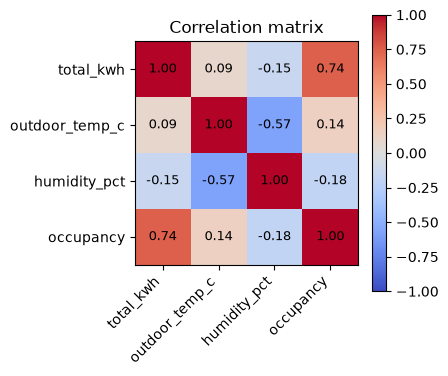

In [13]:
corr_cols = ["total_kwh", "outdoor_temp_c", "humidity_pct", "occupancy"]
corr = readings[corr_cols].corr()
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()


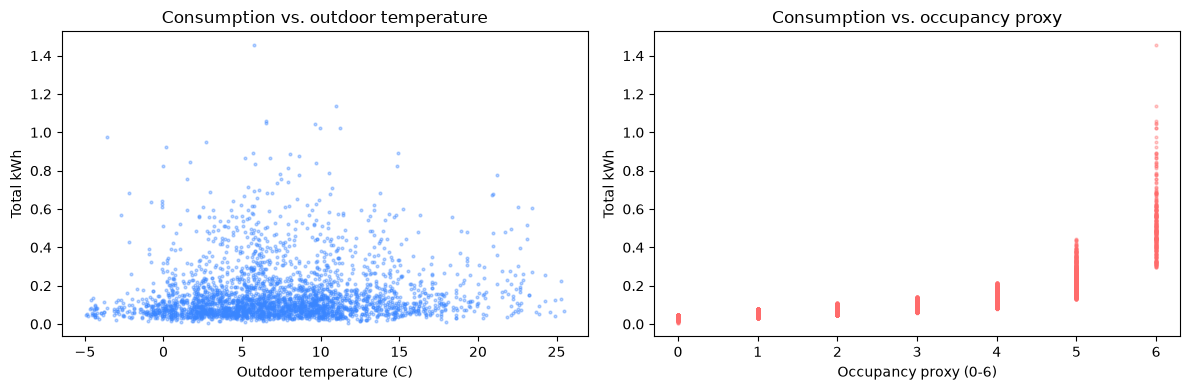

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sample = readings.sample(min(3000, len(readings)), random_state=42)
axes[0].scatter(sample["outdoor_temp_c"], sample["total_kwh"], s=4, alpha=0.35, color="#3a86ff")
axes[0].set_xlabel("Outdoor temperature (C)")
axes[0].set_ylabel("Total kWh")
axes[0].set_title("Consumption vs. outdoor temperature")

axes[1].scatter(sample["occupancy"], sample["total_kwh"], s=4, alpha=0.35, color="#ff6b6b")
axes[1].set_xlabel("Occupancy proxy (0-6)")
axes[1].set_ylabel("Total kWh")
axes[1].set_title("Consumption vs. occupancy proxy")
plt.tight_layout()
plt.show()


## 7. Save the preprocessed dataset

In [15]:
out_path = PROCESSED_DIR / "gridsentry_readings.csv"
readings.to_csv(out_path, index=False)
print(f"Saved {len(readings)} rows to {out_path}")


Saved 13160 rows to data\processed\gridsentry_readings.csv
